**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /data/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /data/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /data/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /data/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/log 
PROJECT REF     (FD_REF): /data/reddylab/Kuei/repo/Proj_ENCODE_FCC/references 



## Prepare

**Set global variable**

In [2]:
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

VEC_TXT_FOLDER = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


In [3]:
TXT_FNAME_ANNOT = "region.annotation.hic_intact_deep.loop.edge.tsv"

**View files**

In [4]:
txt_fdiry = file.path(FD_RES, "region_annotation", "*", "summary")
txt_fname = TXT_FNAME_ANNOT
txt_fglob = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for(txt in vec){cat(txt, "\n")}

/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/region_annotation/fcc_astarr_macs_input_overlap/summary/region.annotation.hic_intact_deep.loop.edge.tsv 
/data/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/region_annotation/fcc_astarr_macs_input_union/summary/region.annotation.hic_intact_deep.loop.edge.tsv 


## Import data

In [5]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry = file.path(FD_RES, "region_annotation", txt_folder, "summary")
    txt_fname = TXT_FNAME_ANNOT
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})
names(lst) = VEC_TXT_FOLDER

### assign and show
lst_dat_region_annot_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111330     28

$fcc_astarr_macs_input_union
[1] 136962     28



Chrom_1,ChromStart_1,ChromEnd_1,Region_1,Chrom_2,ChromStart_2,ChromEnd_2,Region_2,Loop,is_Left2Right,Size,Distance,Observed,ExpectedBL,ExpectedDonut,FdrBL,FdrDonut,LocalObserved,LocalPeakZ,LocalPval,Score_Log2OE,Zcore_Log2OE_by_Mean,Zcore_Log2OE_by_Median,Zcore_Log2OE_by_Mode,Dist_Log10,Dist_Bin,Zcore_Log2OE_by_DistStrat,Zcore_Log2OE_by_DistSmooth
chr1,778233,779389,chr1:778233-779389,chr1,826796,828040,chr1:826796-828040,chr1:778000-779000|chr1:827000-828000,TRUE,1000,49000,16,2.803620,4.147049,1e-07,7.6e-06,8,2.234097,0.0208767,1.947915,0.0112455,0.1422544,0.3979698,4.690196,"[4.5,5)",0.5603609,0.5460845
chr1,869637,870233,chr1:869637-870233,chr1,975975,976656,chr1:975975-976656,chr1:870000-872000|chr1:974000-976000,TRUE,2000,104000,31,10.256543,9.079411,1e-07,0.0e+00,6,4.898979,0.0000000,1.771598,-0.2596009,-0.1140001,0.1417154,5.017033,"[5,5.5)",-0.2752799,-0.3986085
chr1,869637,870233,chr1:869637-870233,chr1,1062315,1062732,chr1:1062315-1062732,chr1:870000-872000|chr1:1062000-1064000,TRUE,2000,193000,24,5.239281,4.773047,0e+00,0.0e+00,5,4.472134,0.0000000,2.330052,0.5982581,0.6976415,0.9533570,5.285557,"[5,5.5)",0.6047244,0.5482221


## Summarize the loop strength by region pair

In [6]:
lst = lst_dat_region_annot_import
lst = lapply(lst, function(dat){
    ### summarize the loop scores and counts
    dat = dat %>% 
        dplyr::mutate(Region_Edge = paste(Region_1, Region_2, sep = "|")) %>%
        dplyr::group_by(
            Chrom_1, ChromStart_1, ChromEnd_1, Region_1, 
            Chrom_2, ChromStart_2, ChromEnd_2, Region_2, 
            Region_Edge
        ) %>%
        dplyr::summarise(
            Loop_Count = dplyr::n_distinct(Loop),
            Loop_Score_Mean = mean(Score_Log2OE, na.rm = TRUE),
            Loop_Score_Sum  =  sum(Score_Log2OE, na.rm = TRUE),
            Loop_Zcore_Global_Mean = mean(Zcore_Log2OE_by_Mode, na.rm = TRUE),
            Loop_Zcore_Global_Sum  =  sum(Zcore_Log2OE_by_Mode, na.rm = TRUE),
            Loop_Zcore_DistSm_Mean = mean(Zcore_Log2OE_by_DistSmooth, na.rm = TRUE),
            Loop_Zcore_DistSm_Sum  =  sum(Zcore_Log2OE_by_DistSmooth, na.rm = TRUE),
            .groups = "drop"
        )    
    return(dat)
})

### assign and show
lst_dat_region_annot_summary = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111329     16

$fcc_astarr_macs_input_union
[1] 136954     16



Chrom_1,ChromStart_1,ChromEnd_1,Region_1,Chrom_2,ChromStart_2,ChromEnd_2,Region_2,Region_Edge,Loop_Count,Loop_Score_Mean,Loop_Score_Sum,Loop_Zcore_Global_Mean,Loop_Zcore_Global_Sum,Loop_Zcore_DistSm_Mean,Loop_Zcore_DistSm_Sum
chr1,778233,779389,chr1:778233-779389,chr1,826796,828040,chr1:826796-828040,chr1:778233-779389|chr1:826796-828040,1,1.947915,1.947915,0.3979698,0.3979698,0.5460845,0.5460845
chr1,869637,870233,chr1:869637-870233,chr1,935793,936234,chr1:935793-936234,chr1:869637-870233|chr1:935793-936234,1,1.128334,1.128334,-0.7931850,-0.7931850,-1.6579968,-1.6579968
chr1,869637,870233,chr1:869637-870233,chr1,975975,976656,chr1:975975-976656,chr1:869637-870233|chr1:975975-976656,1,1.771598,1.771598,0.1417154,0.1417154,-0.3986085,-0.3986085


**Explore: Count/Score distribution**

In [7]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    res = table(dat$Loop_Count, dnn="Loop_Count")
    dat = as.data.frame(res)
    return(dat)
})

dat = bind_rows(lst, .id="Folder")
dat = dat %>% tidyr::spread(Folder, Freq)
fun_display_table(dat)

Loop_Count,fcc_astarr_macs_input_overlap,fcc_astarr_macs_input_union
1,111328,136946
2,1,8


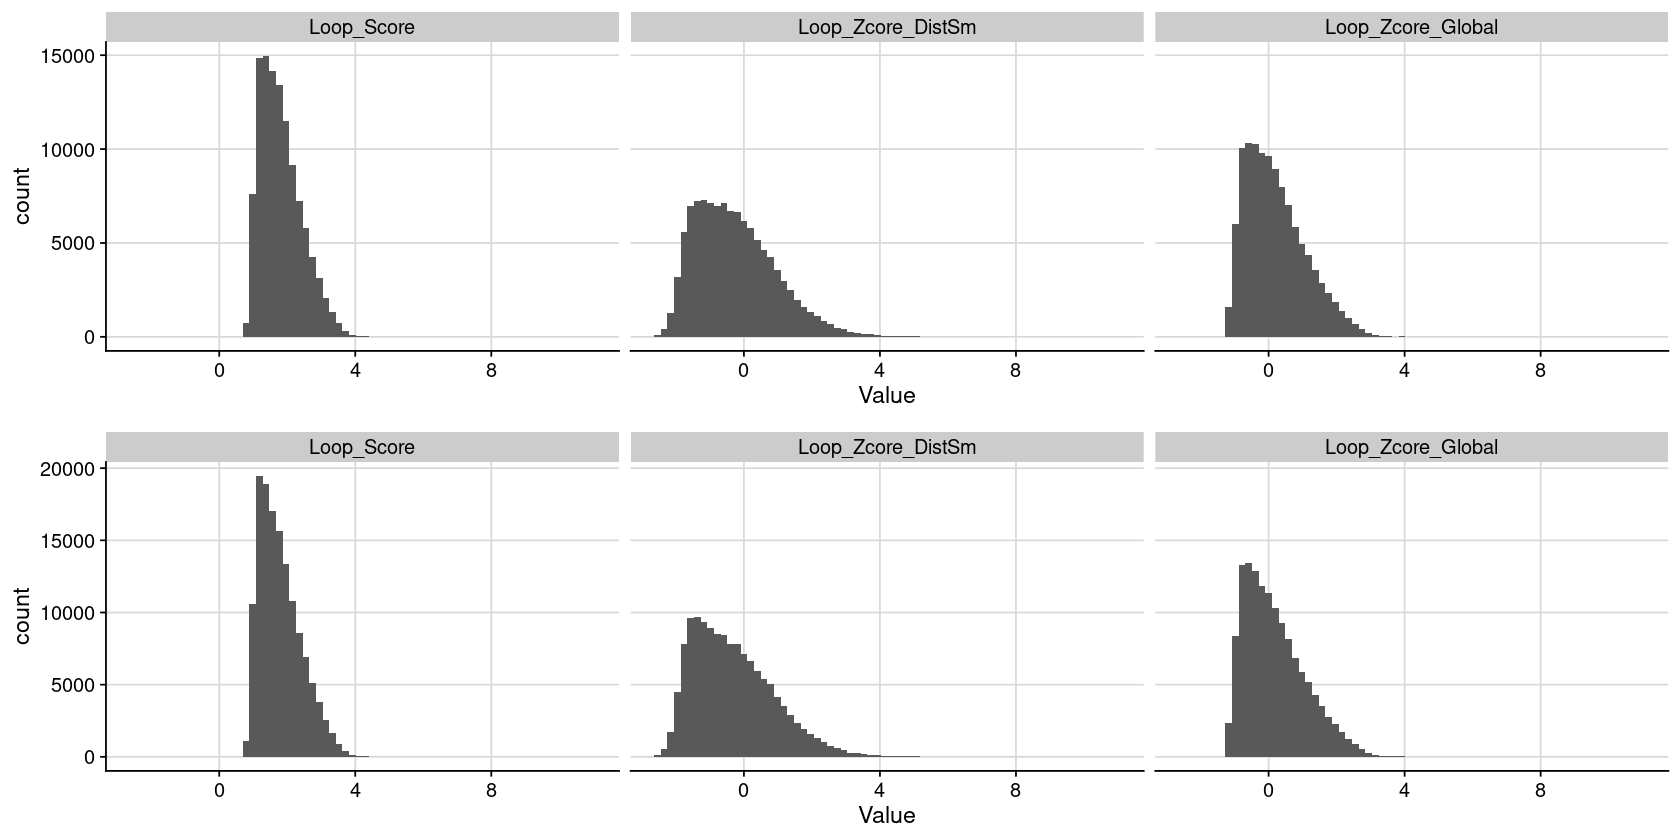

In [10]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    dat = dat %>% 
        dplyr::select(Region_Edge, Loop_Score, Loop_Zcore_Global, Loop_Zcore_DistSm) %>%
        tidyr::gather(Metric, Value, -Region_Edge)
    gpt = ggplot(dat, aes(x=Value)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid() +
        facet_grid(~Metric)
    return(gpt)
})

options(repr.plot.height=7, repr.plot.width=14)
plot_grid(plotlist = lst, ncol=1)

## Export results

In [8]:
for (txt_folder in VEC_TXT_FOLDER){

    ### get table
    dat_region_annot_result = lst_dat_region_annot_summary[[txt_folder]]
    
    ### set file directory
    txt_fdiry = file.path(
        FD_RES, 
        "region_annotation", 
        txt_folder,
        "summary"
    )
    
    ### write region annotation
    txt_fname = "region.annotation.hic_intact_deep.loop.score.edge.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)
    
    dat = dat_region_annot_result
    write_tsv(dat, txt_fpath)
}

In [13]:
lst = lst_dat_region_annot_import
lst = lapply(lst, function(dat){
    dat = dat %>%
        dplyr::group_by(Loop) %>% 
        dplyr::mutate(Pair_Weight = 1/n()) %>% 
        dplyr::ungroup()
    
    ### summarize the loop scores and counts
    dat = dat %>% 
        dplyr::group_by(
            Chrom_1, ChromStart_1, ChromEnd_1, Region_1, 
            Chrom_2, ChromStart_2, ChromEnd_2, Region_2) %>%
        dplyr::summarise(
            Loop_Count = dplyr::n_distinct(Loop),
            Loop_Score = median(Score_Log2OE, na.rm = TRUE),
            Loop_Zcore = median(Zcore_Log2OE_by_Mode, na.rm = TRUE),
            Loop_WMean = sum(Zcore_Log2OE_by_Mode * Pair_Weight, na.rm=TRUE),
            .groups = "drop"
        )    
    return(dat)
})

### assign and show
lst_dat_region_annot_test = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111329     12

$fcc_astarr_macs_input_union
[1] 136954     12



Chrom_1,ChromStart_1,ChromEnd_1,Region_1,Chrom_2,ChromStart_2,ChromEnd_2,Region_2,Loop_Count,Loop_Score,Loop_Zcore,Loop_WMean
chr1,778233,779389,chr1:778233-779389,chr1,826796,828040,chr1:826796-828040,1,1.947915,0.3979698,0.3979698
chr1,869637,870233,chr1:869637-870233,chr1,935793,936234,chr1:935793-936234,1,1.128334,-0.7931850,-0.7931850
chr1,869637,870233,chr1:869637-870233,chr1,975975,976656,chr1:975975-976656,1,1.771598,0.1417154,0.1417154


In [14]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    res = table(dat$Loop_Count, dnn="Loop_Count")
    dat = as.data.frame(res)
    return(dat)
})

dat = bind_rows(lst, .id="Folder")
dat = dat %>% tidyr::spread(Folder, Freq)
fun_display_table(dat)

Loop_Count,fcc_astarr_macs_input_overlap,fcc_astarr_macs_input_union
1,111328,136946
2,1,8


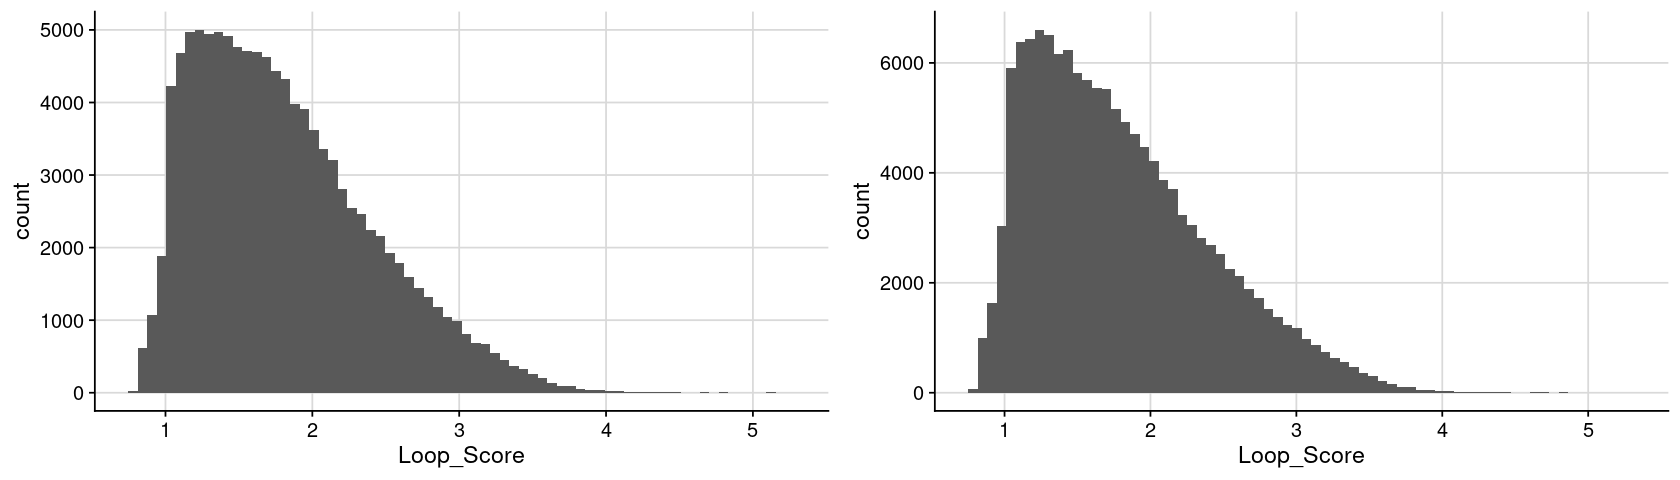

In [15]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

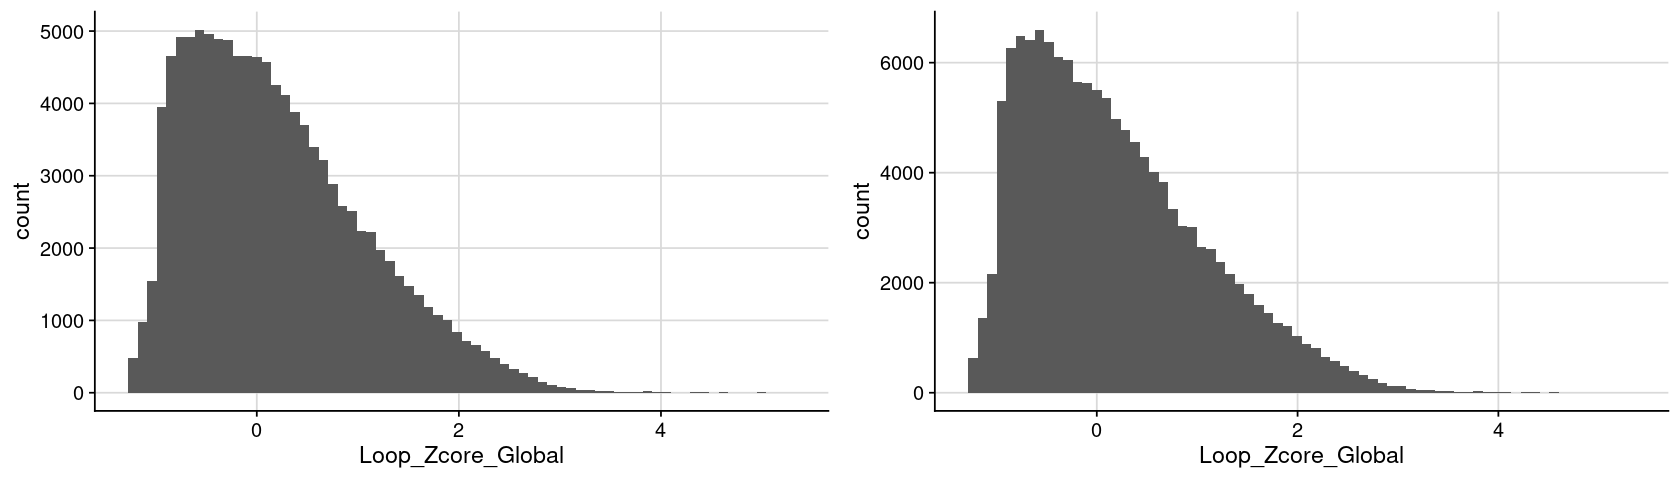

In [16]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_Global)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

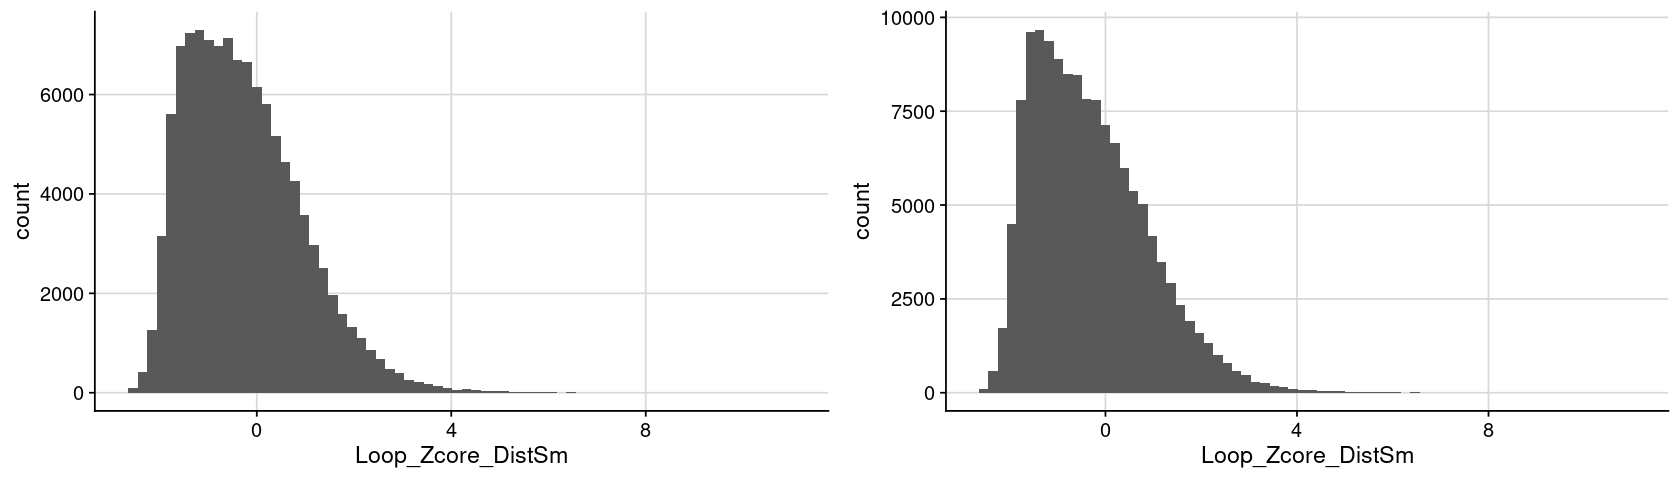

In [17]:
lst = lst_dat_region_annot_summary
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore_DistSm)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

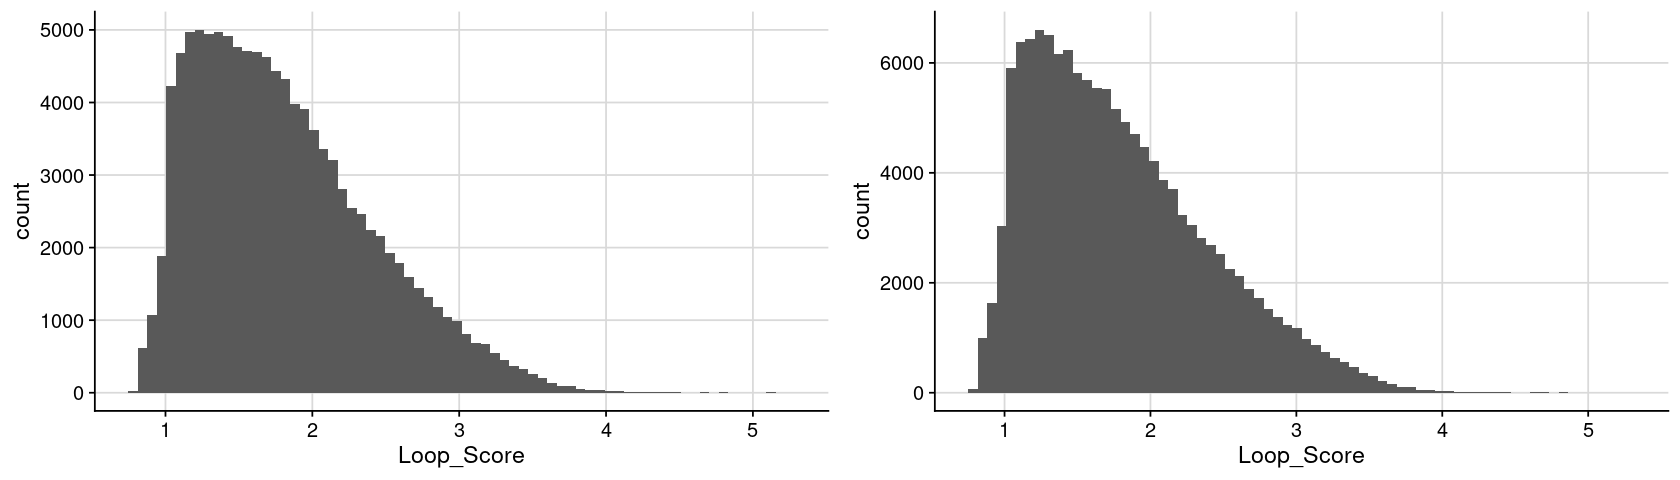

In [15]:
lst = lst_dat_region_annot_test
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Score)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

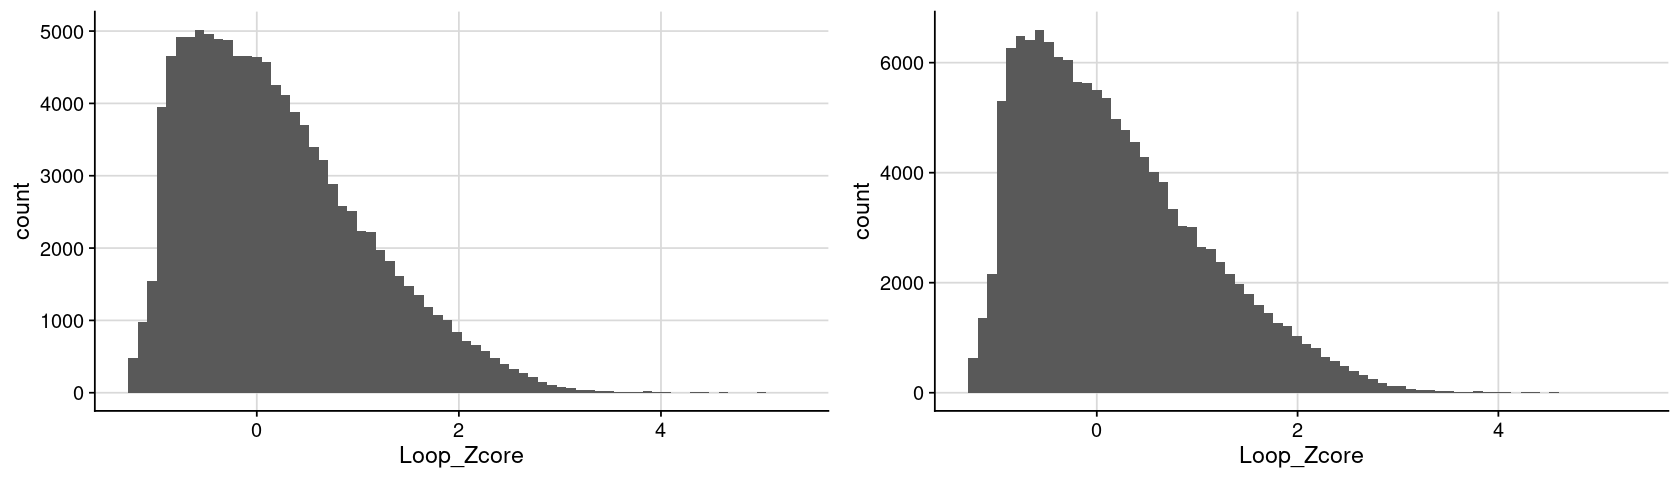

In [16]:
lst = lst_dat_region_annot_test
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

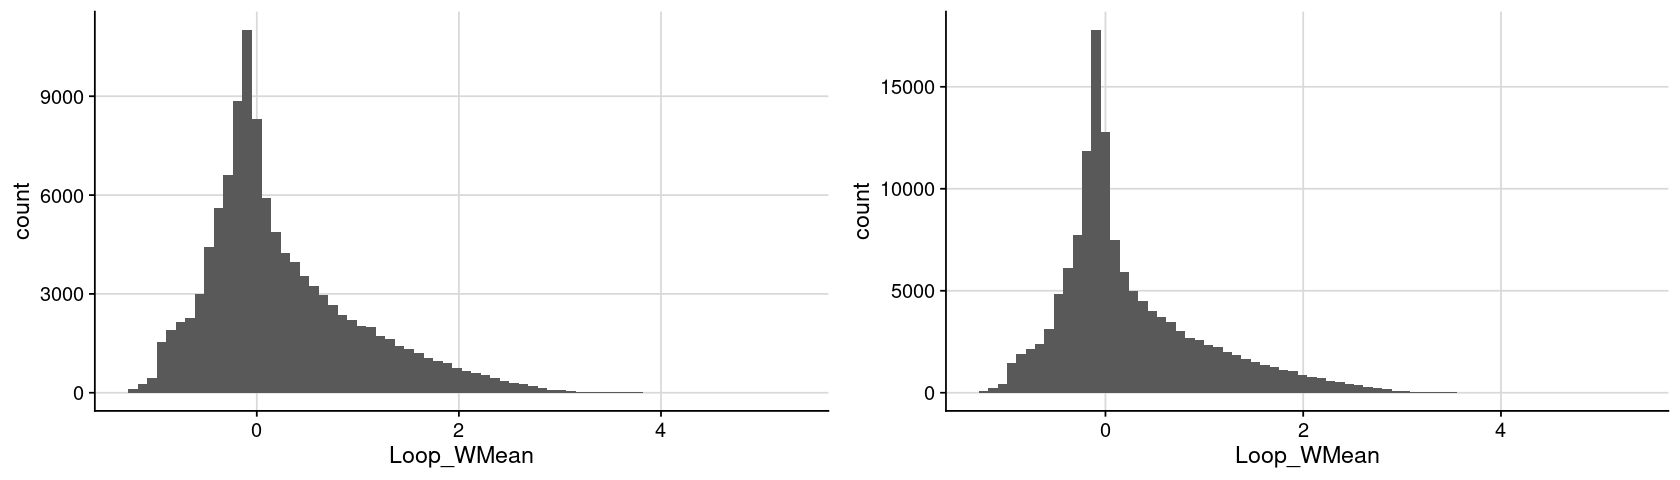

In [17]:
lst = lst_dat_region_annot_test
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_WMean)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

## Arrange table

In [24]:
lst = lst_dat_region_annot_import
lst = lapply(lst, function(dat){
    ### 
    tmp = split(dat, dat$Label)
    vec = c(
        "Loop", "Size", "Distance", 
        "Observed", "ExpectedBL", "ExpectedDonut", "FdrBL", "FdrDonut", 
        "LocalObserved", "LocalPeakZ", "LocalPval")
    
    ###
    vec_txt_cname1 = c("Region",   vec)
    vec_txt_cname2 = c("Region_A", vec)
    vec_txt_loopup = setNames(vec_txt_cname1, vec_txt_cname2)
    
    dat = tmp$Loop_A
    dat = dat %>% 
        dplyr::select(!!!vec_txt_cname1) %>% 
        dplyr::rename(all_of(vec_txt_loopup))
    dat_loop_A = dat

    ###
    vec_txt_cname1 = c("Region",   vec)
    vec_txt_cname2 = c("Region_B", vec)
    vec_txt_loopup = setNames(vec_txt_cname1, vec_txt_cname2)
    
    dat = tmp$Loop_B
    dat = dat %>% 
        dplyr::select(!!!vec_txt_cname1) %>% 
        dplyr::rename(all_of(vec_txt_loopup))
    dat_loop_B = dat
    
    ### get all loops for each region
    dat = dplyr::inner_join(dat_loop_A, dat_loop_B, by = "Loop", relationship = "many-to-many") 
    dat = dat %>% dplyr::distinct()
    return(dat)
})

### assign and show
lst_dat_region_annot_arrange = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111330      3

$fcc_astarr_macs_input_union
[1] 136962      3



Region_A,Loop,Region_B
chr1:778233-779389,chr1:778000-779000|chr1:827000-828000,chr1:826796-828040
chr1:869637-870233,chr1:870000-872000|chr1:974000-976000,chr1:975975-976656
chr1:869637-870233,chr1:870000-872000|chr1:1062000-1064000,chr1:1062315-1062732


In [25]:
lst = lst_dat_region_annot_arrange
lst = lapply(lst, function(dat){
    dat = dat %>%
        dplyr::mutate(
            Region_1 = pmin(Region_A, Region_B),
            Region_2 = pmax(Region_A, Region_B)
        ) %>%
        dplyr::select(Loop, Region_1, Region_2) %>%
        dplyr::distinct()
    return(dat)
})

### assign and show
lst_dat_region_annot_rmdup = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 111330      3

$fcc_astarr_macs_input_union
[1] 136962      3



Loop,Region_1,Region_2
chr1:778000-779000|chr1:827000-828000,chr1:778233-779389,chr1:826796-828040
chr1:870000-872000|chr1:974000-976000,chr1:869637-870233,chr1:975975-976656
chr1:870000-872000|chr1:1062000-1064000,chr1:1062315-1062732,chr1:869637-870233


In [28]:
lst = lst_dat_region_annot_arrange
lst = lapply(lst, function(dat){
    tmp = dat %>% 
        dplyr::filter(Region_A == Region_B) %>% 
        dplyr::distinct() 
    num_self_linked_loop = nrow(tmp)
    
    tmp = dat %>% 
        dplyr::filter(Region_A == Region_B) %>% 
        dplyr::select(Region_A, Region_B) %>% 
        dplyr::distinct()
    num_self_linked_region = nrow(tmp)

    res = data.frame(
        "Count_SelfEdge_Loop"   = num_self_linked_loop,
        "Count_SelfEdge_Region" = num_self_linked_region
    )
    return(res)
})

dat = bind_rows(lst, .id = "Folder")
fun_display_table(dat)

Folder,Count_SelfEdge_Loop,Count_SelfEdge_Region
fcc_astarr_macs_input_overlap,0,0
fcc_astarr_macs_input_union,0,0


In [26]:
lst = lst_dat_region_annot_rmdup
lst = lapply(lst, function(dat){
    tmp = dat %>% 
        dplyr::filter(Region_1 == Region_2) %>% 
        dplyr::distinct() 
    num_self_linked_loop = nrow(tmp)
    
    tmp = dat %>% 
        dplyr::filter(Region_1 == Region_2) %>% 
        dplyr::select(Region_1, Region_2) %>% 
        dplyr::distinct()
    num_self_linked_region = nrow(tmp)

    res = data.frame(
        "Count_SelfEdge_Loop"   = num_self_linked_loop,
        "Count_SelfEdge_Region" = num_self_linked_region
    )
    return(res)
})

dat = bind_rows(lst, .id = "Folder")
fun_display_table(dat)

Folder,Count_SelfEdge_Loop,Count_SelfEdge_Region
fcc_astarr_macs_input_overlap,0,0
fcc_astarr_macs_input_union,0,0


In [17]:
lst = lst_dat_region_annot_arrange
dat = lst[[1]]

dat = dat %>% 
    dplyr::filter(Region_1 == Region_2) %>% 
    dplyr::distinct() 
head(dat)

Region_1,Loop,Region_2
<chr>,<chr>,<chr>


In [23]:
lst = lst_dat_region_annot_arrange
dat = lst[[1]]

dat = dat %>%
    dplyr::rowwise() %>%
    dplyr::mutate(
        Region_A = min(Region_1, Region_2),
        Region_B = max(Region_1, Region_2)
    ) %>%
    dplyr::select(Loop, Region_A, Region_B) %>%
    dplyr::distinct()

dat = dat %>% 
    dplyr::filter(Region_A == Region_B) %>% 
    dplyr::distinct() 
head(dat)

Loop,Region_A,Region_B
<chr>,<chr>,<chr>


In [19]:
lst = lst_dat_region_annot_arrange
dat = lst[[1]]

dat = dat %>% dplyr::filter(Region_1 == "chr1:1062315-1062732")
head(dat)

Region_1,Loop,Region_2
<chr>,<chr>,<chr>


In [21]:
lst = lst_dat_region_annot_arrange
dat = lst[[1]]

dat = dat %>% dplyr::filter(Region_2 == "chr1:1062315-1062732")
fun_display_table(dat)

Region_1,Loop,Region_2
chr1:869637-870233,chr1:870000-872000|chr1:1062000-1064000,chr1:1062315-1062732
chr1:903783-905204,chr1:904000-905000|chr1:1062000-1063000,chr1:1062315-1062732
chr1:920937-921509,chr1:920000-925000|chr1:1060000-1065000,chr1:1062315-1062732
chr1:923427-925161,chr1:920000-925000|chr1:1060000-1065000,chr1:1062315-1062732
chr1:1040162-1041454,chr1:1040000-1041000|chr1:1062000-1063000,chr1:1062315-1062732


### Explore: Number of self-looping edge

In [11]:
lst = lst_dat_region_annot_arrange
lst = lapply(lst, function(dat){
    tmp = dat %>% 
        dplyr::filter(Region_1 == Region_2) %>% 
        dplyr::distinct() 
    num_self_linked_loop = nrow(tmp)
    
    tmp = dat %>% 
        dplyr::filter(Region_1 == Region_2) %>% 
        dplyr::select(Region_1, Region_2) %>% 
        dplyr::distinct()
    num_self_linked_region = nrow(tmp)

    res = data.frame(
        "Count_SelfEdge_Loop"   = num_self_linked_loop,
        "Count_SelfEdge_Region" = num_self_linked_region
    )
    return(res)
})

dat = bind_rows(lst, .id = "Folder")
fun_display_table(dat)

Folder,Count_SelfEdge_Loop,Count_SelfEdge_Region
fcc_astarr_macs_input_overlap,0,0
fcc_astarr_macs_input_union,0,0


In [13]:
lst = lst_dat_region_annot_arrange
lst = lapply(lst, function(dat){

    dat = dat %>%
        dplyr::rowwise() %>%
        dplyr::mutate(
            Region_1 = min(Region_1, Region_2),
            Region_2 = max(Region_1, Region_2)
        ) %>%
        dplyr::select(Loop, Region_1, Region_2) %>%
        dplyr::distinct()
    
    tmp = dat %>% 
        dplyr::filter(Region_1 == Region_2) %>% 
        dplyr::distinct() 
    num_self_linked_loop = nrow(tmp)
    
    tmp = dat %>% 
        dplyr::filter(Region_1 == Region_2) %>% 
        dplyr::select(Region_1, Region_2) %>% 
        dplyr::distinct()
    num_self_linked_region = nrow(tmp)

    res = data.frame(
        "Count_SelfEdge_Loop"   = num_self_linked_loop,
        "Count_SelfEdge_Region" = num_self_linked_region
    )
    return(res)
})

dat = bind_rows(lst, .id = "Folder")
fun_display_table(dat)

Folder,Count_SelfEdge_Loop,Count_SelfEdge_Region
fcc_astarr_macs_input_overlap,717,391
fcc_astarr_macs_input_union,862,463


### Explore: Number of Loop

In [12]:
lst = lst_dat_region_annot_arrange
dat = lst[[1]]
dat = dat %>%
    count(Loop) %>%
    arrange(desc(n))
head(dat)

Loop,n
<chr>,<int>
chr1:34780000-34790000|chr1:35140000-35150000,24
chr2:64640000-64650000|chr2:65360000-65370000,20
chr3:195620000-195630000|chr3:196510000-196520000,20
chr7:129950000-129960000|chr7:130910000-130920000,20
chr7:149770000-149780000|chr7:151080000-151090000,20
chr7:2400000-2410000|chr7:5420000-5430000,20


In [13]:
lst = lst_dat_region_annot_arrange
dat = lst[[1]]
dat = dat %>%
  mutate(Region_pair = ifelse(Region_1 < Region_2,
                              paste(Region_1, Region_2, sep="|"),
                              paste(Region_2, Region_1, sep="|"))) %>%
  count(Region_pair) %>%
  arrange(desc(n))
head(dat)

Region_pair,n
<chr>,<int>
chr6:20291639-20292598|chr6:20401119-20404711,2
chr10:100009244-100010395|chr10:99845750-99846458,1
chr10:100009244-100010395|chr10:99983369-99984091,1
chr10:100046000-100046575|chr10:100433460-100434388,1
chr10:100046000-100046575|chr10:99560458-99560929,1
chr10:100046000-100046575|chr10:99731780-99733121,1


In [14]:
lst = lst_dat_region_annot_arrange
dat = lst[[1]]
dat <- dat %>%
  mutate(
    Region_1 = pmin(Region_1, Region_2),
    Region_2 = pmax(Region_1, Region_2)
  ) %>%
  select(Loop, Region_1, Region_2) %>%
  distinct()

dat = dat %>%
  mutate(Region_pair = ifelse(Region_1 < Region_2,
                              paste(Region_1, Region_2, sep="|"),
                              paste(Region_2, Region_1, sep="|"))) %>%
  count(Region_pair) %>%
  arrange(desc(n))
head(dat)

Region_pair,n
<chr>,<int>
chr3:10321964-10322737|chr3:10321964-10322737,11
chr3:10320551-10321588|chr3:10320551-10321588,10
chr3:10025798-10027023|chr3:10025798-10027023,8
chr6:10435295-10435526|chr6:10435295-10435526,7
chr7:100081205-100083003|chr7:100081205-100083003,7
chr1:10032429-10033763|chr1:10032429-10033763,6


## Count the number of loop

In [66]:
lst = lst_dat_region_annot_arrange
lst = lapply(lst, function(dat){
    ### summarize the loop scores and counts
    dat = dat %>% 
        dplyr::group_by(Chrom, ChromStart, ChromEnd, Region) %>%
        dplyr::summarise(
            Loop_Count         = n(),
            Loop_Log2OE_Mean   = mean(Log2OE),
            Loop_Log2OE_Median = median(Log2OE),
            .groups = "drop"
        )

    ### standardize loop scores
    vec = dat$Loop_Log2OE_Median
    num_med = median(vec, na.rm = TRUE)
    vec = abs(vec - num_med)
    num_mad = median(vec, na.rm = TRUE) * 1.4826

    vec = dat$Loop_Log2OE_Median
    obj_dens = density(dat$Loop_Log2OE_Median, na.rm = TRUE)
    num_mode = obj_dens$x[which.max(obj_dens$y)]
    
    dat = dat %>%
        dplyr::mutate(
            Loop_Score = Loop_Log2OE_Median,
            #Loop_Zcore = (Loop_Log2OE_Median - num_med) / num_mad,
            Loop_Zcore = (Loop_Log2OE_Median - num_mode) / num_mad,
        )
    
    ### choose and label the score
    dat = dat %>%
        dplyr::mutate(
            Loop_Score_Label = "Median(Log2OE)",
            Loop_Zcore_Label = "(Score−Mode)/MAD"
        )
    return(dat)
})

### assign and show
lst_dat_region_score_loop = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
fun_display_table(head(dat, 3))

$fcc_astarr_macs_input_overlap
[1] 53760    11

$fcc_astarr_macs_input_union
[1] 65084    11



Chrom,ChromStart,ChromEnd,Region,Loop_Count,Loop_Log2OE_Mean,Loop_Log2OE_Median,Loop_Score,Loop_Zcore,Loop_Score_Label,Loop_Zcore_Label
chr1,778233,779389,chr1:778233-779389,1,1.947915,1.947915,1.947915,0.7580134,Median(Log2OE),(Score−Mode)/MAD
chr1,826796,828040,chr1:826796-828040,1,1.947915,1.947915,1.947915,0.7580134,Median(Log2OE),(Score−Mode)/MAD
chr1,869637,870233,chr1:869637-870233,4,1.938149,2.050825,2.050825,0.9652739,Median(Log2OE),(Score−Mode)/MAD


**Explore: Differences between using mean and median**

In [60]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    dat = dat %>% dplyr::mutate(Delta = (Loop_Log2OE_Median - Loop_Log2OE_Mean) / ((Loop_Log2OE_Median + Loop_Log2OE_Mean)/2))
    res = summary(dat$Delta)
    return(res)
})

print(lst)

$fcc_astarr_macs_input_overlap
    Min.  1st Qu.   Median     Mean  3rd Qu.     Max. 
-0.60178 -0.01985  0.00000 -0.01032  0.00000  0.25889 

$fcc_astarr_macs_input_union
     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
-0.601784 -0.011822  0.000000 -0.009225  0.000000  0.258892 



In [61]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    res = summary(dat$Loop_Zcore)
    return(res)
})

print(lst)

$fcc_astarr_macs_input_overlap
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-1.5374 -0.4001  0.2343  0.3511  0.9600  7.4588 

$fcc_astarr_macs_input_union
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
-1.2843 -0.2489  0.3819  0.5158  1.1214  7.5115 



## Explore: count/score distribution

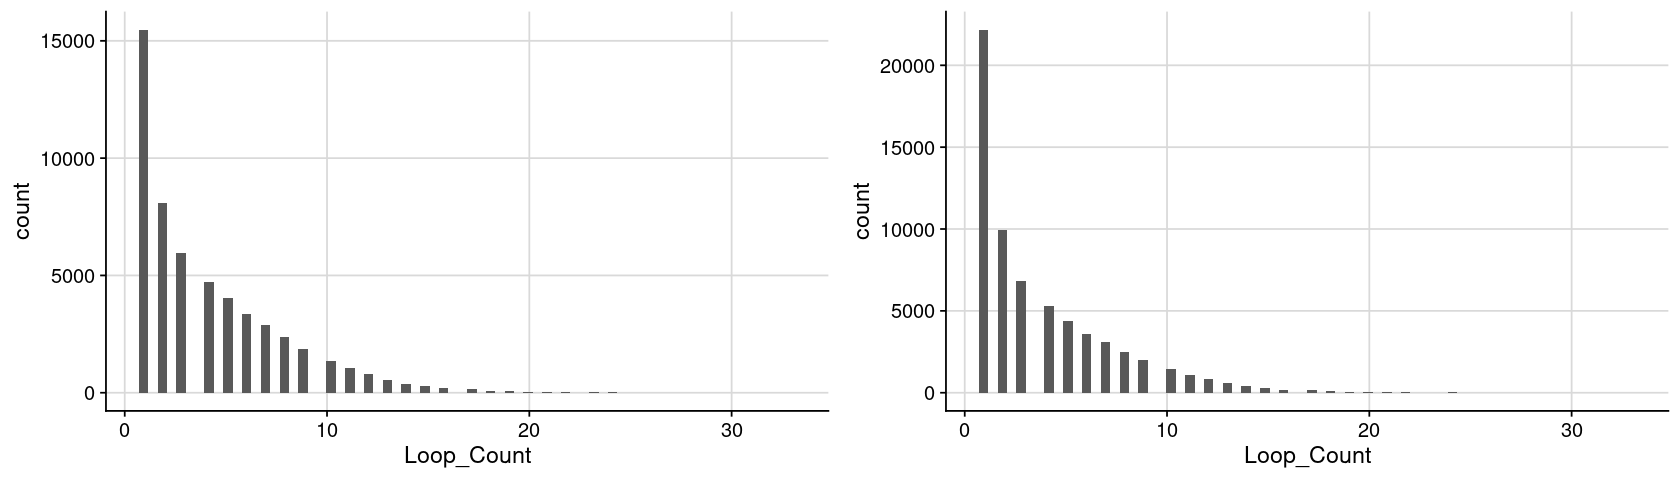

In [62]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Count)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

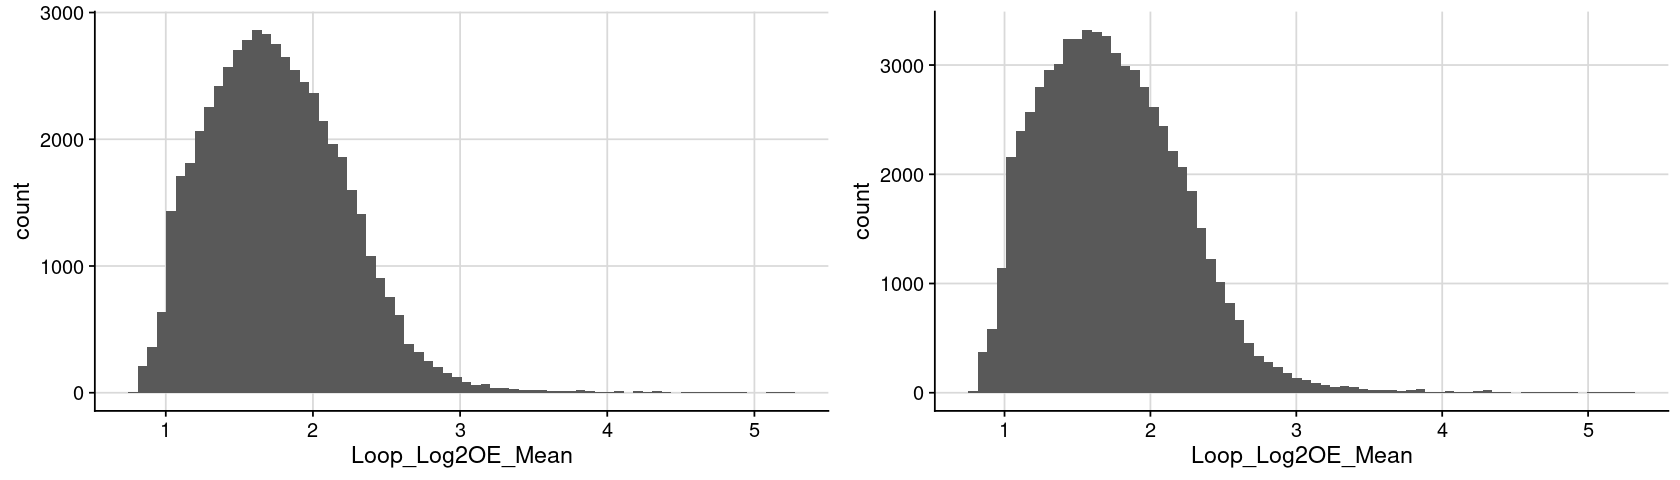

In [63]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Log2OE_Mean)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

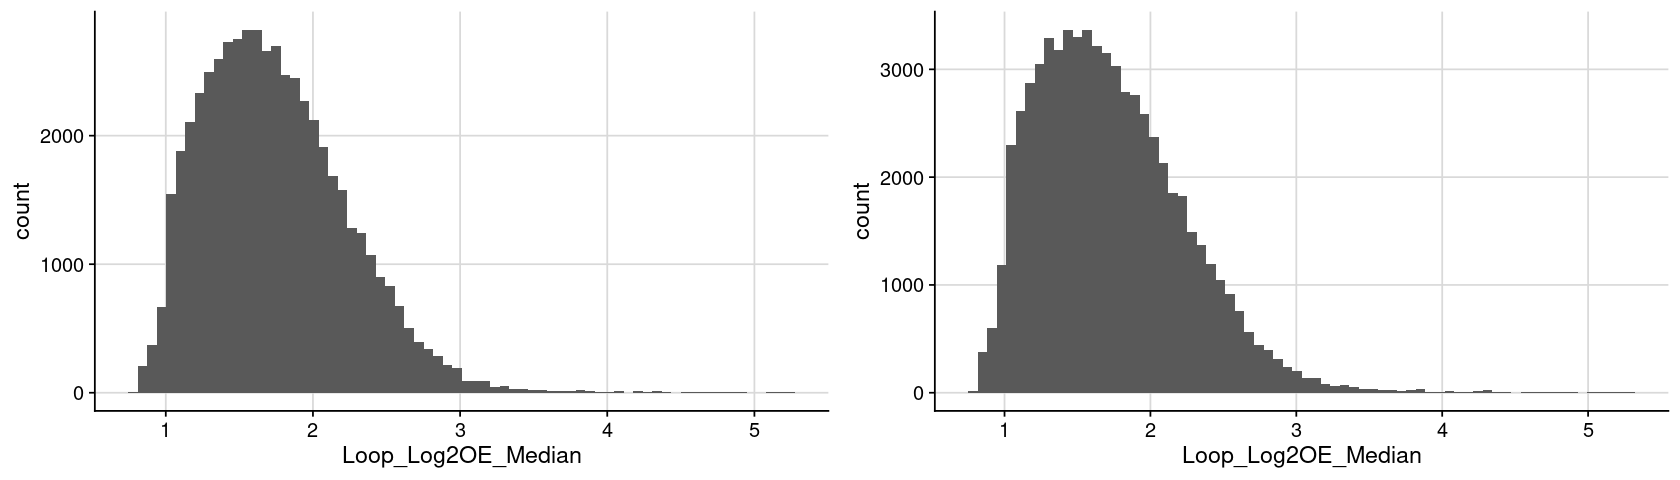

In [64]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Log2OE_Median)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

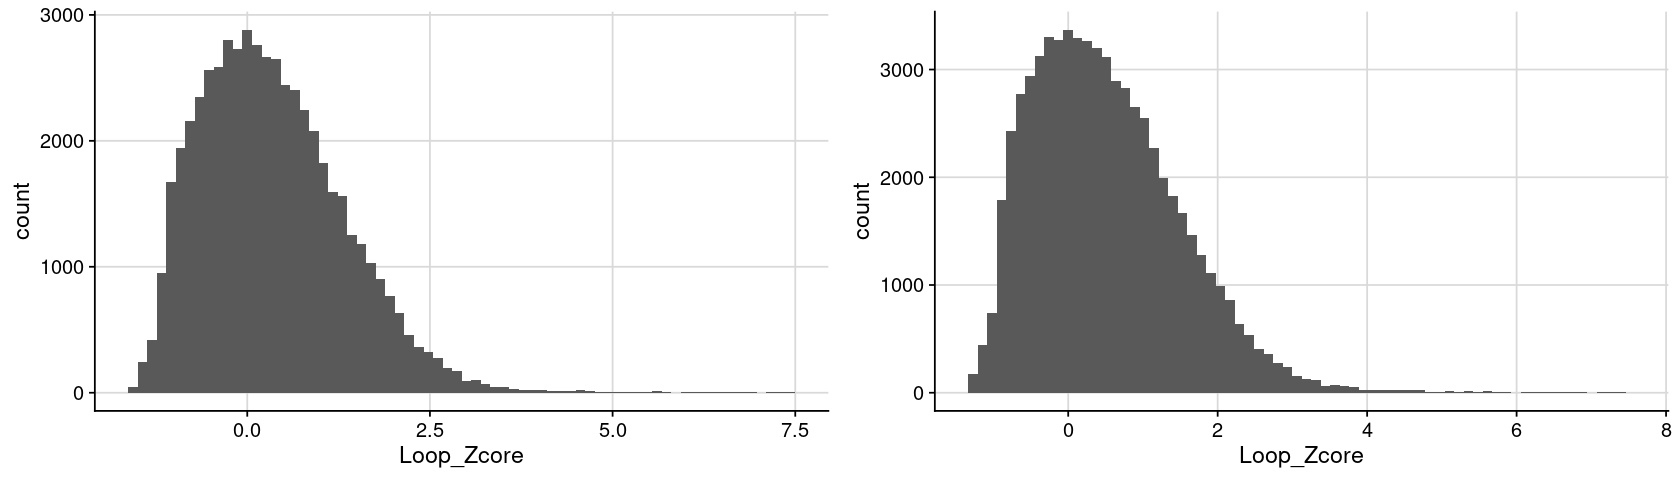

In [65]:
lst = lst_dat_region_score_loop
lst = lapply(lst, function(dat){
    gpt = ggplot(dat, aes(x=Loop_Zcore)) +
        geom_histogram(bins = 70) +
        theme_cowplot() +
        background_grid()
    return(gpt)
})

options(repr.plot.height=4, repr.plot.width=14)
plot_grid(plotlist = lst, nrow=1)

```
Left panel (raw scores): shows the raw distribution of your Loop_Score.

Red dashed line = median.

Blue dashed line = mode estimate from kernel density.

Right panel (robust z-scores): shows the distribution after (x − mode)/MAD.

Blue dashed line = 0 (the shifted peak).

If things worked correctly, the histogram peak should now sit very close to zero.
```

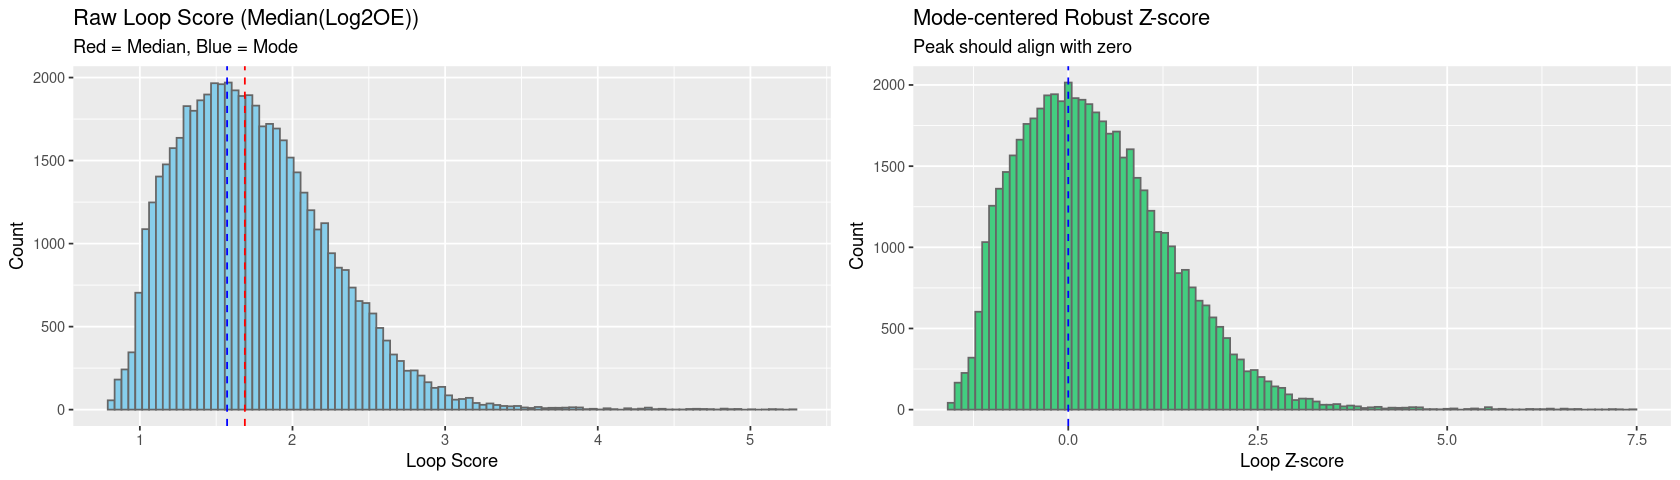

In [67]:
dat <- lst_dat_region_score_loop[[1]]  # pick one dataset

# Histogram of raw scores
p1 <- ggplot(dat, aes(x = Loop_Score)) +
  geom_histogram(bins = 100, fill = "skyblue", color = "grey40") +
  geom_vline(aes(xintercept = median(Loop_Score, na.rm = TRUE)),
             color = "red", linetype = "dashed") +
  geom_vline(aes(xintercept = density(Loop_Score)$x[which.max(density(Loop_Score)$y)]),
             color = "blue", linetype = "dashed") +
  labs(title = "Raw Loop Score (Median(Log2OE))",
       subtitle = "Red = Median, Blue = Mode",
       x = "Loop Score", y = "Count")

# Histogram of z-scores (mode-centered, MAD-scaled)
p2 <- ggplot(dat, aes(x = Loop_Zcore)) +
  geom_histogram(bins = 100, fill = "seagreen3", color = "grey40") +
  geom_vline(xintercept = 0, color = "blue", linetype = "dashed") +
  labs(title = "Mode-centered Robust Z-score",
       subtitle = "Peak should align with zero",
       x = "Loop Z-score", y = "Count")

# Show side by side
plot_grid(p1, p2, nrow=1)

## Export results

In [68]:
for (txt_folder in VEC_TXT_FOLDER){

    ### get table
    dat_region_annot_result = lst_dat_region_score_loop[[txt_folder]]
    
    ### set file directory
    txt_fdiry = file.path(
        FD_RES, 
        "region_annotation", 
        txt_folder,
        "summary"
    )
    
    ### write region annotation
    txt_fname = "region.annotation.hic_intact_deep.loop.score.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)
    
    dat = dat_region_annot_result
    write_tsv(dat, txt_fpath)
}